In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Bitcoin Price Prediction/bitcoin.csv')
print(df.head())
print(df.shape)
print(df.describe())
print(df.info())

         Date        Open        High  ...       Close   Adj Close    Volume
0  2014-09-17  465.864014  468.174011  ...  457.334015  457.334015  21056800
1  2014-09-18  456.859985  456.859985  ...  424.440002  424.440002  34483200
2  2014-09-19  424.102997  427.834991  ...  394.795990  394.795990  37919700
3  2014-09-20  394.673004  423.295990  ...  408.903992  408.903992  36863600
4  2014-09-21  408.084991  412.425995  ...  398.821014  398.821014  26580100

[5 rows x 7 columns]
(2713, 7)
               Open          High  ...     Adj Close        Volume
count   2713.000000   2713.000000  ...   2713.000000  2.713000e+03
mean   11311.041069  11614.292482  ...  11323.914637  1.470462e+10
std    16106.428891  16537.390649  ...  16110.365010  2.001627e+10
min      176.897003    211.731003  ...    178.102997  5.914570e+06
25%      606.396973    609.260986  ...    606.718994  7.991080e+07
50%     6301.569824   6434.617676  ...   6317.609863  5.098183e+09
75%    10452.399414  10762.644531  ..

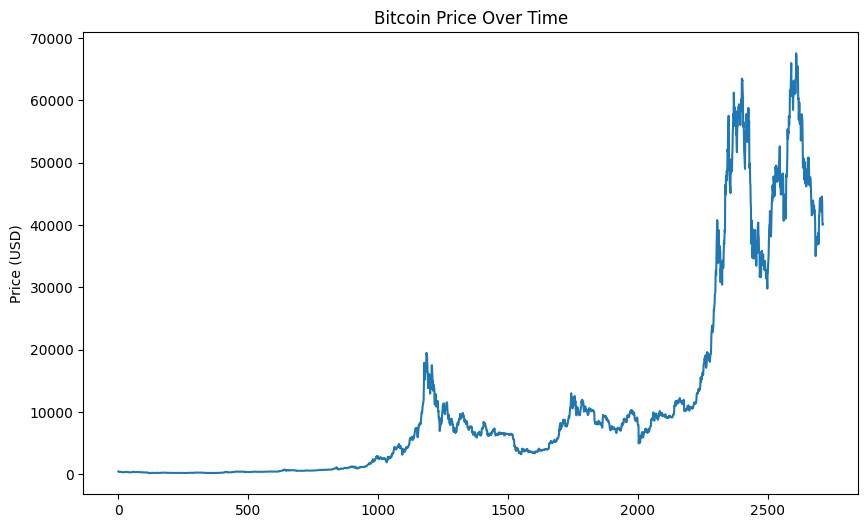

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(df['Close'])
plt.title('Bitcoin Price Over Time')
plt.ylabel('Price (USD)')
plt.show()

In [10]:
df[df['Close'] == df['Adj Close']].shape
print(df.shape)
df = df.drop('Adj Close', axis=1)
df.isnull().sum()

(2713, 7)


,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0


<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

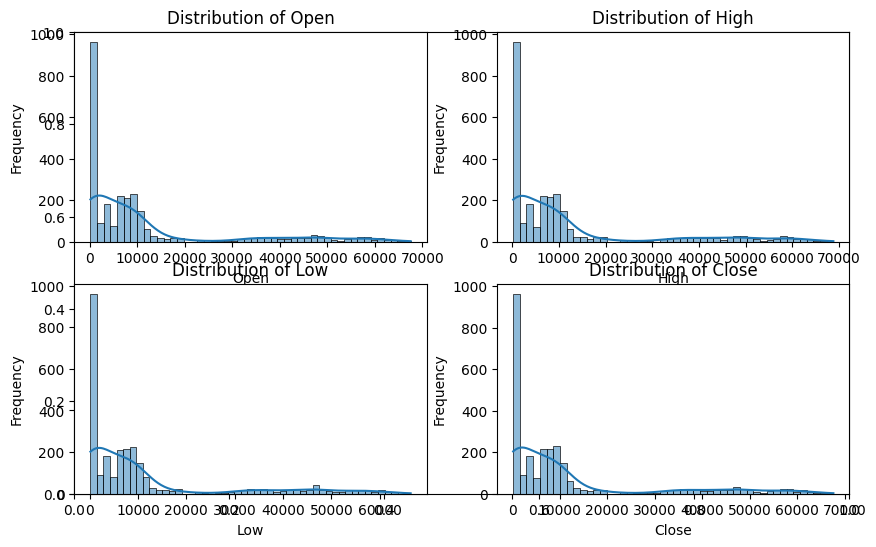

In [12]:
FEATURES = ['Open', 'High', 'Low', 'Close']

plt.subplots(figsize=(10, 6))
for i, col in enumerate(FEATURES):
    plt.subplot(2, 2, i+1)
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout

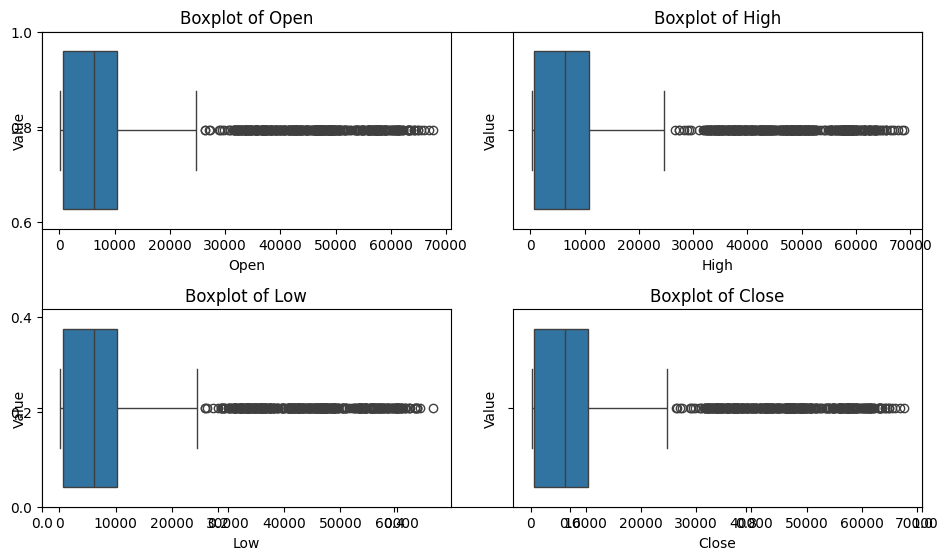

In [14]:
plt.subplots(figsize=(10, 6))
for i, col in enumerate(FEATURES):
  plt.subplot(2, 2, i+1)
  sns.boxplot(df[col].dropna(), orient='h')
  plt.title(f'Boxplot of {col}')
  plt.xlabel(col)
  plt.ylabel('Value')
plt.tight_layout()

In [15]:
splitted_date = df['Date'].str.split('-', expand=True)
df['year'] = splitted_date[0].astype(int)
df['month'] = splitted_date[1].astype(int)
df['day'] = splitted_date[2].astype(int)
df['Date'] = pd.to_datetime(df['Date'])

df.head()

,Date,Open,High,Low,Close,Volume,year,month,day
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800,2014,9,17
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200,2014,9,18
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700,2014,9,19
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,36863600,2014,9,20
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,26580100,2014,9,21


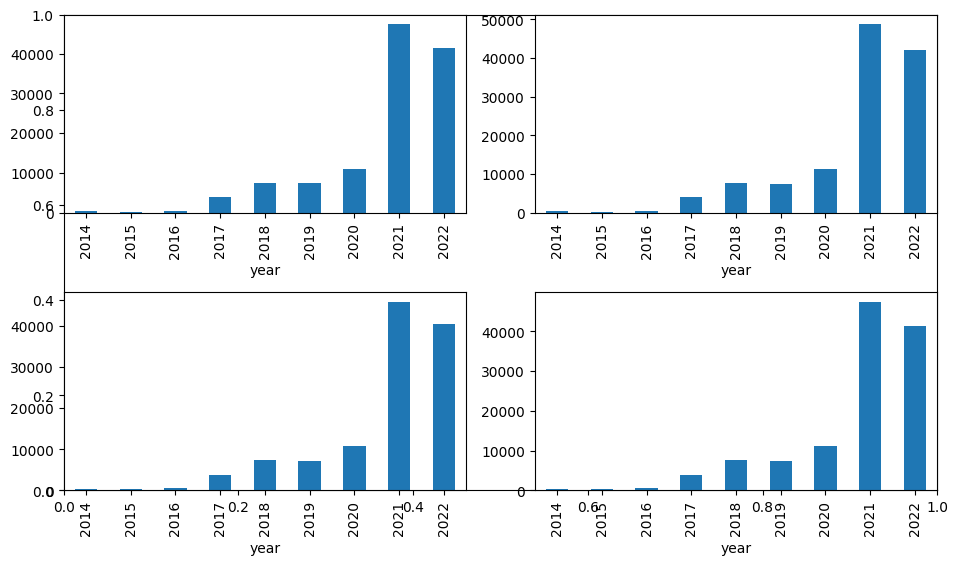

In [17]:
grouped_data = df.groupby('year').mean()

plt.subplots(figsize=(10, 6))
for i, col in enumerate(FEATURES):
  plt.subplot(2, 2, i+1)
  grouped_data[col].plot(kind='bar')
plt.tight_layout()

In [18]:
df['is_quarter_end'] = np.where(df['month']%3 == 0, 1, 0)
df.head()

,Date,Open,High,Low,Close,Volume,year,month,day,is_quarter_end
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800,2014,9,17,1
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200,2014,9,18,1
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700,2014,9,19,1
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,36863600,2014,9,20,1
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,26580100,2014,9,21,1


In [19]:
df['open-close'] = df['Open'] - df['Close']
df['low-high'] = df['Low'] - df['High']
df['target'] = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)
df.head()

,Date,Open,High,Low,Close,Volume,year,month,day,is_quarter_end,open-close,low-high,target
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800,2014,9,17,1,8.529999,-15.752014,0
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200,2014,9,18,1,32.419983,-43.755981,0
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700,2014,9,19,1,29.307007,-43.302978,1
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,36863600,2014,9,20,1,-14.230988,-33.412994,0
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,26580100,2014,9,21,1,9.263977,-19.244995,1


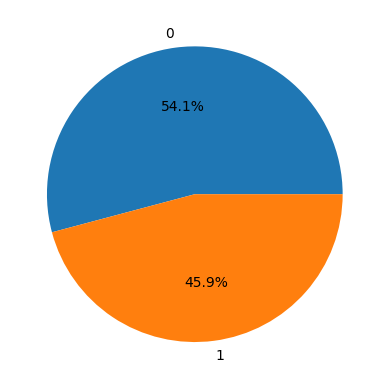

In [20]:
plt.pie(df['target'].value_counts().values,
        labels=[0, 1], autopct='%1.1f%%')
plt.show()

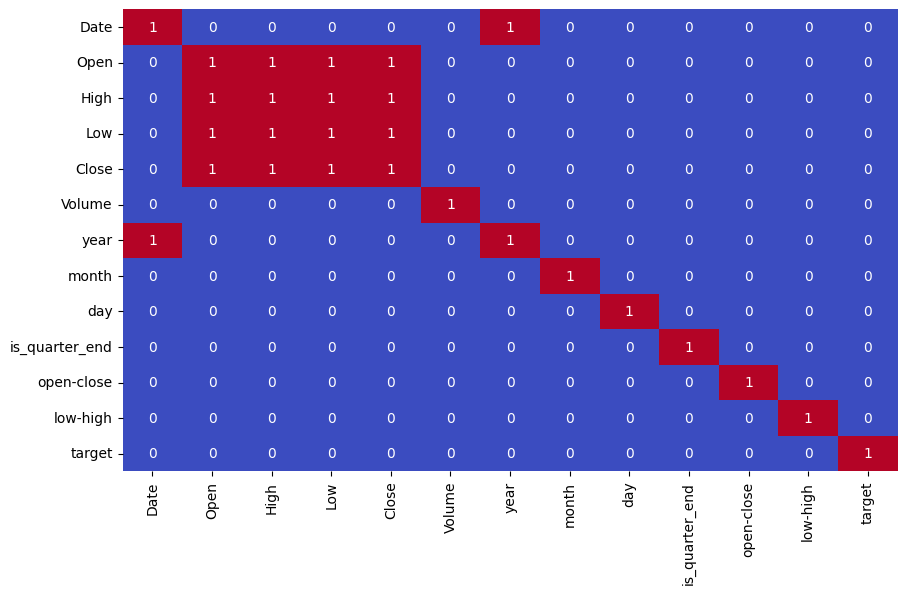

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr() > 0.9, annot=True, cmap='coolwarm', cbar=False)
plt.show()

In [24]:
feature_list = df[['open-close', 'low-high', 'is_quarter_end']]
target_list = df['target']

scaler = StandardScaler()
feature_list = scaler.fit_transform(feature_list)

X_train, X_test, Y_train, Y_test = train_test_split(feature_list, target_list, test_size=0.2, random_state=42)

LogisticRegression():
Accuracy: 0.5543278084714549
Confusion Matrix:
[[ 16 223]
 [ 19 285]]
Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.07      0.12       239
           1       0.56      0.94      0.70       304

    accuracy                           0.55       543
   macro avg       0.51      0.50      0.41       543
weighted avg       0.52      0.55      0.44       543




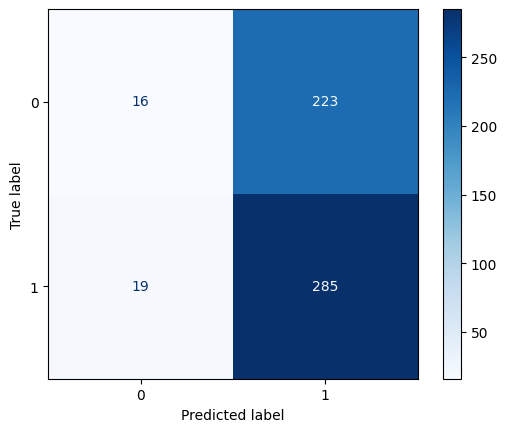

SVC():
Accuracy: 0.5580110497237569
Confusion Matrix:
[[ 20 219]
 [ 21 283]]
Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.08      0.14       239
           1       0.56      0.93      0.70       304

    accuracy                           0.56       543
   macro avg       0.53      0.51      0.42       543
weighted avg       0.53      0.56      0.46       543




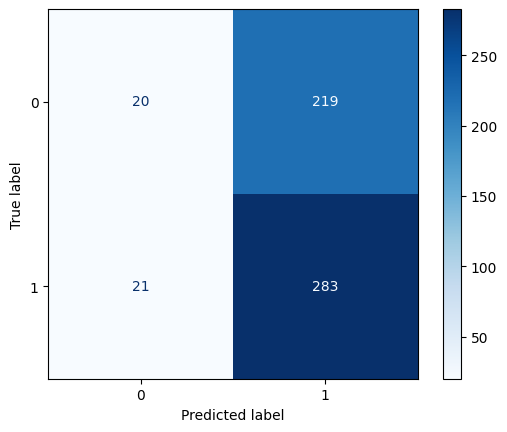

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...):
Accuracy: 0.48987108655616945
Confusion Matrix:
[[ 85 154]
 [123 181]]
Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.36      0.38       239
           1       0.54      0.60   

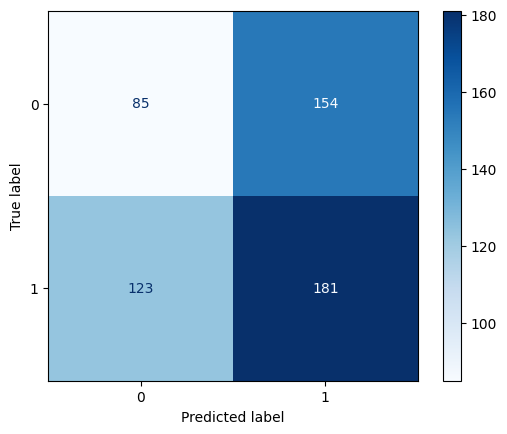

In [28]:
models = [LogisticRegression(), SVC(), XGBClassifier()]

for model in models:
  model.fit(X_train, Y_train)
  Y_pred = model.predict(X_test)
  accuracy = accuracy_score(Y_test, Y_pred)

  print(f"{model}:")
  print(f"Accuracy: {accuracy}")
  print(f"Confusion Matrix:\n{confusion_matrix(Y_test, Y_pred)}")
  print(f"Classification Report:\n{classification_report(Y_test, Y_pred)}\n")

  ConfusionMatrixDisplay.from_estimator(model, X_test, Y_test, cmap='Blues')
  plt.show()